# 11-loyiha
Tibbiy startap prototipi va pilot natijalari

startup_pilot.csv: sun’iy ekspert yorliqlari, model ballari va vaqt o‘lchovlari. KPIlar haqiqiy klinik yoki biznes natijasi emas.


In [1]:
# Tibbiy startap prototipi va pilot natijalari
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def main():
    path = DATA / "startup_pilot.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 400
        truth = rng.binomial(1, .3, n)
        score = np.clip(.18 + .6 * truth + rng.normal(0, .18, n), 0, 1)
        baseline = rng.gamma(3, 6, n)
        assisted = baseline * rng.uniform(.55, .95, n)
        ai_label = score >= .5
        overrides = ai_label != truth
        pd.DataFrame({"case_id": np.arange(n), "y_true": truth,
            "ai_probability": score, "turnaround_min": assisted,
            "baseline_min": baseline, "override": overrides,
            "site": rng.choice(["SYN_A", "SYN_B"], n)}).to_csv(
            path, index=False)
    df = pd.read_csv(path)
    if df.case_id.duplicated().any():
        raise ValueError("case_id takrorlangan")
    probability = df.ai_probability.to_numpy()
    if not np.isfinite(probability).all() or not (
            (probability >= 0) & (probability <= 1)).all():
        raise ValueError("Model ballari [0,1] oralig‘ida bo‘lishi kerak")
    metrics = binary_metrics(df.y_true, probability)
    metrics.update({"source": "synthetic",
        "median_turnaround_min": float(df.turnaround_min.median()),
        "median_baseline_min": float(df.baseline_min.median()),
        "override_fraction": float(df.override.mean()),
        "saved_hours_in_simulation": float(
            (df.baseline_min - df.turnaround_min).sum() / 60)})
    save_json("pilot_kpi.json", metrics)
    sites = df.groupby("site").agg(n=("case_id", "size"),
        median_turnaround=("turnaround_min", "median"),
        override_rate=("override", "mean"))
    sites.to_csv(OUT / "site_summary.csv")
    df[["baseline_min", "turnaround_min"]].boxplot()
    plt.ylabel("Daqiqa")
    plt.title("Sun’iy pilot: juft vaqt o‘lchovlari")
    save_plot("pilot_turnaround.png")
    proposal = (
        "# Tibbiy tasvirlar navbatini ko‘rib chiqish prototipi\n\n"
        "Foydalanuvchi: mutaxassis. Chiqish: ko‘rib chiqish navbati.\n"
        "Jarayon: tasvir → sifat nazorati → model → mutaxassis tasdig‘i.\n"
        "Pilot: avval kuzatuv rejimi; qarorlar mutaxassisda qoladi.\n"
        "KPI: vaqt, xatolar, override ulushi va tizim mavjudligi.\n"
        "To‘xtatish mezoni oldindan klinik hamkor bilan belgilanadi.\n"
        "Natijalar sun’iy; foyda yoki klinik samaradorlik isbotlanmagan.\n")
    (OUT / "project_proposal.md").write_text(proposal, encoding="utf-8")
    print(json.dumps(metrics, indent=2))

if __name__ == "__main__":
    main()


{
  "n": 400,
  "threshold": 0.5,
  "accuracy": 0.96,
  "precision": 0.9243697478991597,
  "recall": 0.9401709401709402,
  "specificity": 0.9681978798586572,
  "f1": 0.9322033898305084,
  "roc_auc": 0.994654344477666,
  "brier": 0.06391256242406848,
  "tn": 274,
  "fp": 9,
  "fn": 7,
  "tp": 110,
  "source": "synthetic",
  "median_turnaround_min": 11.661050640545636,
  "median_baseline_min": 15.82615963376145,
  "override_fraction": 0.04,
  "saved_hours_in_simulation": 28.38108421051801
}


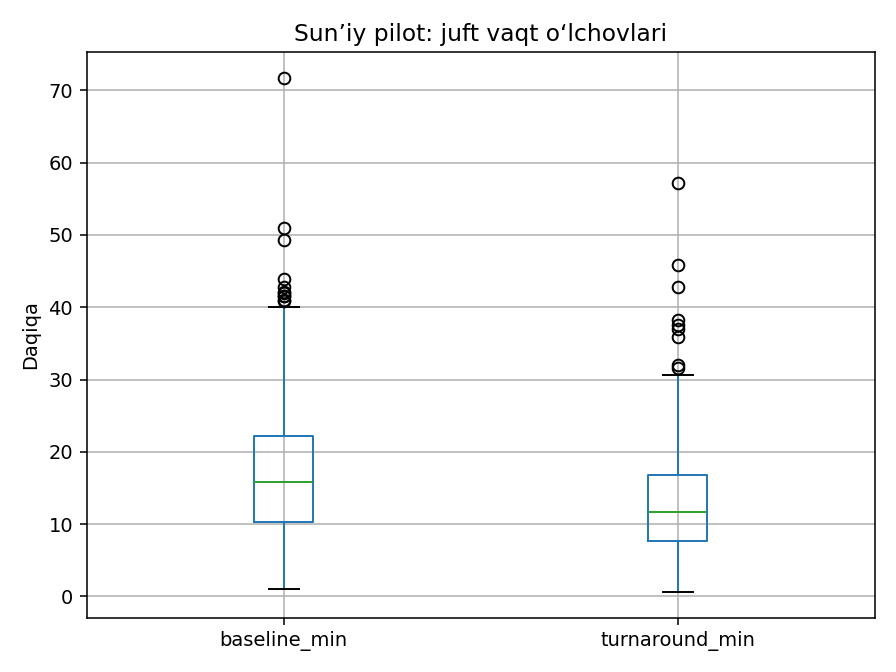

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
